# SFO 2018 passenger experience: a guided case study
**Question:** Which parts of the passenger experience deserve follow-up, and how do problems relate to recommendation?

Real source: 2,809 responses, 97 fields, and the supplied DataSF dictionary. This is historical 2018 evidence. Start with the coding rules and response bases, then examine the business implications. All headline estimates use the supplied weights.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'sfo_cx').exists():
    raise RuntimeError('Run from the project root or notebooks folder.')
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT))
from scripts.download_data import download
from sfo_cx.analysis import prepare, estimate, summarize, by_group, usage_sensitivity, rating_associations, standardized_nps, audit, SERVICES
csv, dictionary = download()
raw = pd.read_csv(csv)
df = prepare(raw)
print(f'{len(df):,} respondents and {len(raw.columns)} source fields')

2,809 respondents and 97 source fields


## 1. Understand the questions
Q7 uses a 1-5 rating scale, anchored by unacceptable and outstanding. Q14 uses a 1-5 difficulty scale. Recommendation uses 0-10 and supports NPS. Yes/No and multi-code questions follow different rules.

A rating, willingness to recommend, service usage and a problem report are related but distinct constructs. Do not invent a single satisfaction score from all of them.

In [2]:
info = audit(raw, df, csv, dictionary)
print('Headers cleaned:', info['header_names_with_outer_whitespace'])
print('Duplicate respondent IDs:', info['duplicate_ids_n'])
print('Missing/nonpositive weights:', info['missing_weights_n'], info['nonpositive_weights_n'])
display(pd.DataFrame(info['rating_audit']).T)
print('Valid NPS:', info['nps_valid_n'], '| code 11 blanks:', info['nps_blank_11_n'])

Headers cleaned: ['Q14FIND ', 'NETPRO  ']
Duplicate respondent IDs: 0
Missing/nonpositive weights: 0 0
Valid NPS: 2650 | code 11 blanks: 159


,valid_1_to_5_n,zero_blank_n,six_not_applicable_n,missing_or_nonnumeric_n,unexpected_numeric_n
Q7ART,2160,124,525,0,0
Q7FOOD,2342,93,374,0,0
Q7STORE,2277,124,408,0,0
Q7SIGN,2648,101,60,0,0
Q7WALKWAY,2537,98,174,0,0
Q7SCREENS,2611,108,90,0,0
Q7INFODOWN,1518,145,1146,0,0
Q7INFOUP,1529,166,1114,0,0
Q7WIFI,2074,131,604,0,0
Q7ROADS,1772,177,860,0,0


## 2. Prepare explicit response bases
Exclude 0, 6 and missing/BLANK values from the 1-5 ratings. Keep 0 for recommendation, because it is a real detractor score. Exclude recommendation code 11. Q15PROBLEM has Yes=1, No=2, Don't know=3 and blank=0.

The clean dataframe adds valid-base flags and nullable outcomes. Original files remain unchanged. Unknown outcomes remain NA rather than becoming False.

In [3]:
print('Overall rating outcomes, including NA:')
display(df.positive_Q7ALL.value_counts(dropna=False).rename('respondents').to_frame())
print('Problem outcomes, including NA:')
display(df.has_problem.value_counts(dropna=False).rename('respondents').to_frame())
print('NPS respondent categories:')
display(summarize(df, ['promoters','passives','detractors','nps'])[['label','unit','n','value']].round(3))

Overall rating outcomes, including NA:
Problem outcomes, including NA:
NPS respondent categories:


,respondents
positive_Q7ALL,
True,2059
False,566
<NA>,184


,respondents
has_problem,
False,2247
True,369
<NA>,193


,label,unit,n,value
0,Promoters: recommendation 9-10,percent,2650,50.699
1,Passives: recommendation 7-8,percent,2650,33.715
2,Detractors: recommendation 0-6,percent,2650,15.586
3,Net Promoter Score,points,2650,35.114


## 3. Calculate an estimate by hand, then check the reusable function
A weighted share divides positive-response weights by all valid-response weights. n remains an actual respondent count.

NPS is the weighted promoter percentage minus detractor percentage. It is measured in points, not percent, and does not measure observed loyalty.

Overall rating 4/5: 80.4852% | NPS: +35.1136 points


,label,unit,n,value
0,Airport overall: rating 4 or 5,percent,2625,80.485
1,Net Promoter Score,points,2650,35.114
2,Reported a problem,percent,2616,12.882


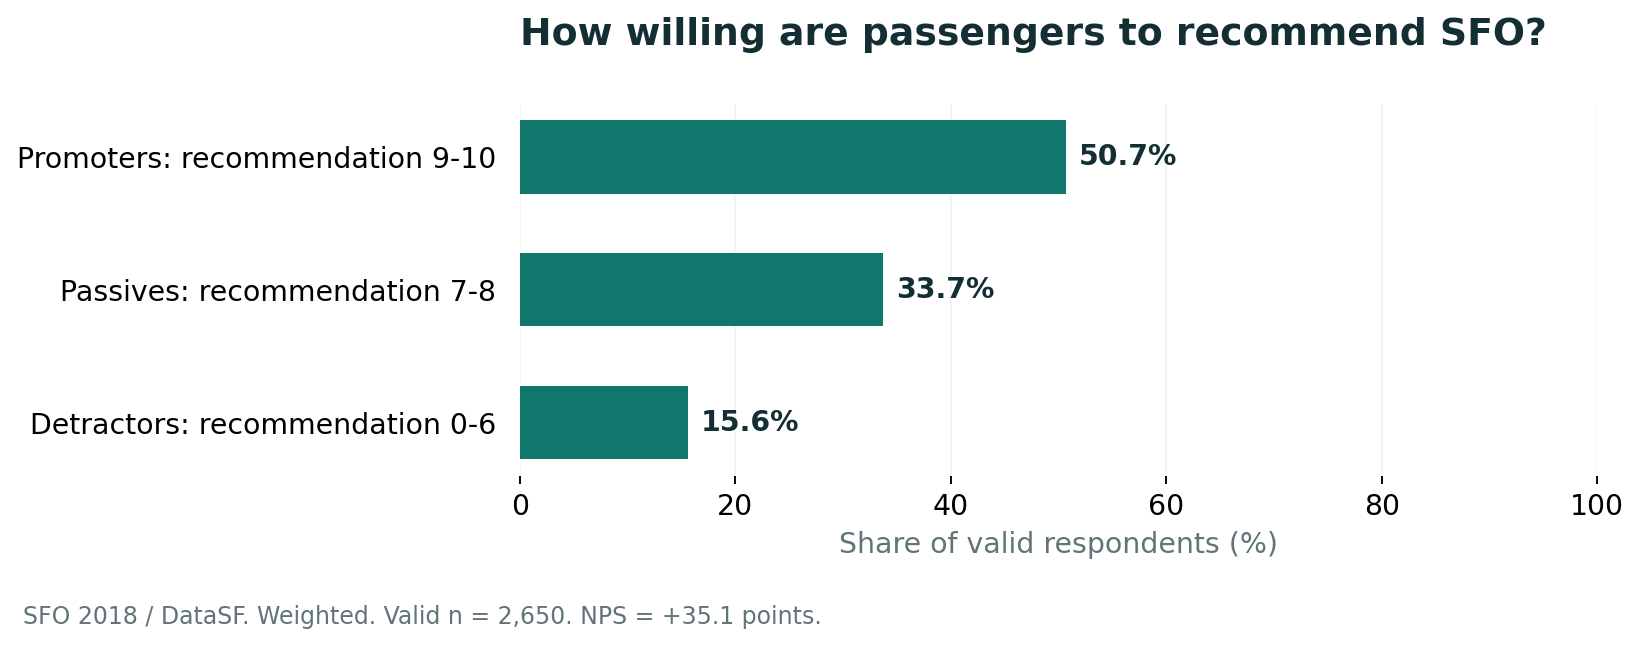

In [4]:
base = df.loc[df.valid_Q7ALL]
top_two = base.Q7ALL.ge(4)
overall_pct = 100 * base.loc[top_two, 'WEIGHT'].sum() / base.WEIGHT.sum()
rec = df.loc[df.valid_nps]
nps = 100 * (rec.loc[rec.NETPRO.ge(9), 'WEIGHT'].sum() - rec.loc[rec.NETPRO.le(6), 'WEIGHT'].sum()) / rec.WEIGHT.sum()
assert abs(overall_pct - estimate(df, 'overall_top2')['value']) < 1e-10
assert abs(nps - estimate(df, 'nps')['value']) < 1e-10
print(f'Overall rating 4/5: {overall_pct:.4f}% | NPS: {nps:+.4f} points')
display(summarize(df, ['overall_top2','nps','problem_rate'])[['label','unit','n','value']].round(3))
display(Image(filename=str(ROOT / 'outputs/figures/01_recommendation.png')))

## 4. Compare recommendation by problem status
Use valid NPS scores within each explicit Yes/No problem group. Unknown problem answers remain outside this comparison even if NPS is valid.

The observed gap is about 43 points. It does not prove that a problem caused that entire difference: trip disruption, service exposure and broader sentiment may contribute.

Valid NPS with an unknown/non-substantive problem answer: 110


,group,label,unit,n,value
0,Reported a problem,Net Promoter Score,points,359,-1.905
1,Reported a problem,Airport overall: rating 4 or 5,percent,345,68.296
2,Reported no problem,Net Promoter Score,points,2181,41.461
3,Reported no problem,Airport overall: rating 4 or 5,percent,2136,82.593


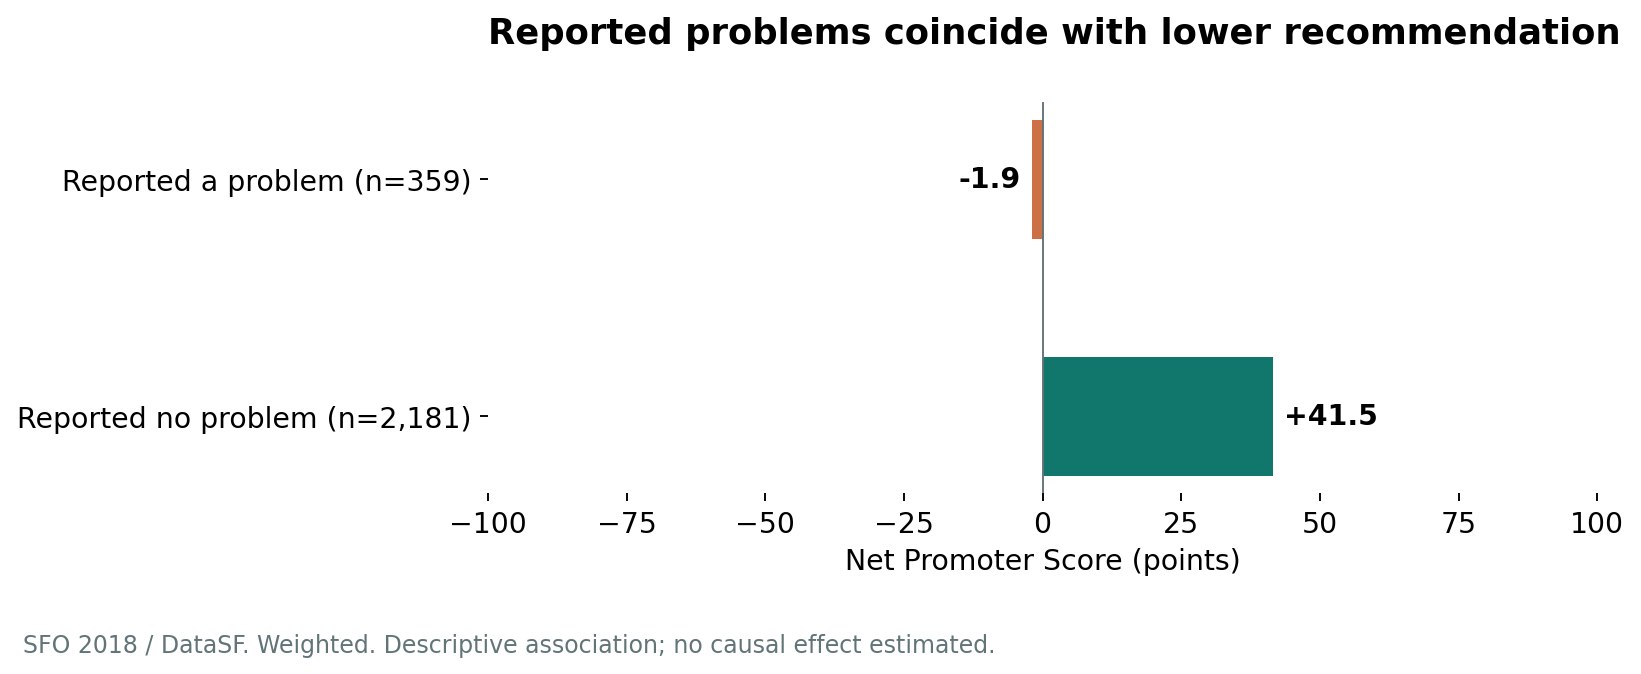

In [5]:
groups = by_group(df, 'problem_status', ['nps','overall_top2'])
display(groups[['group','label','unit','n','value']].round(3))
display(Image(filename=str(ROOT / 'outputs/figures/02_nps_by_problem.png')))
print('Valid NPS with an unknown/non-substantive problem answer:',
      int((df.valid_nps & ~df.valid_problem).sum()))

## 5. Understand coded problem themes
Q15-1 to Q15-3 can supply several codes for the same person. Group the original dictionary codes into themes, then count each person once per theme. Use all 369 Yes problem reporters as the denominator, including 15 with no recognized theme.

These are existing coded responses, not an AI sentiment model. A frequent theme does not establish that the airport alone controls it.

Problem reporters without a recognized theme: 15


,label,n,value
3,Security and immigration,369,35.809
0,Directions and information,369,19.815
5,Gate changes and delays,369,14.466
4,Airline experience,369,10.044
2,Airport amenities,369,7.357
1,Restaurants and services,369,6.741
7,Other problems,369,3.050
6,Disability assistance,369,2.234


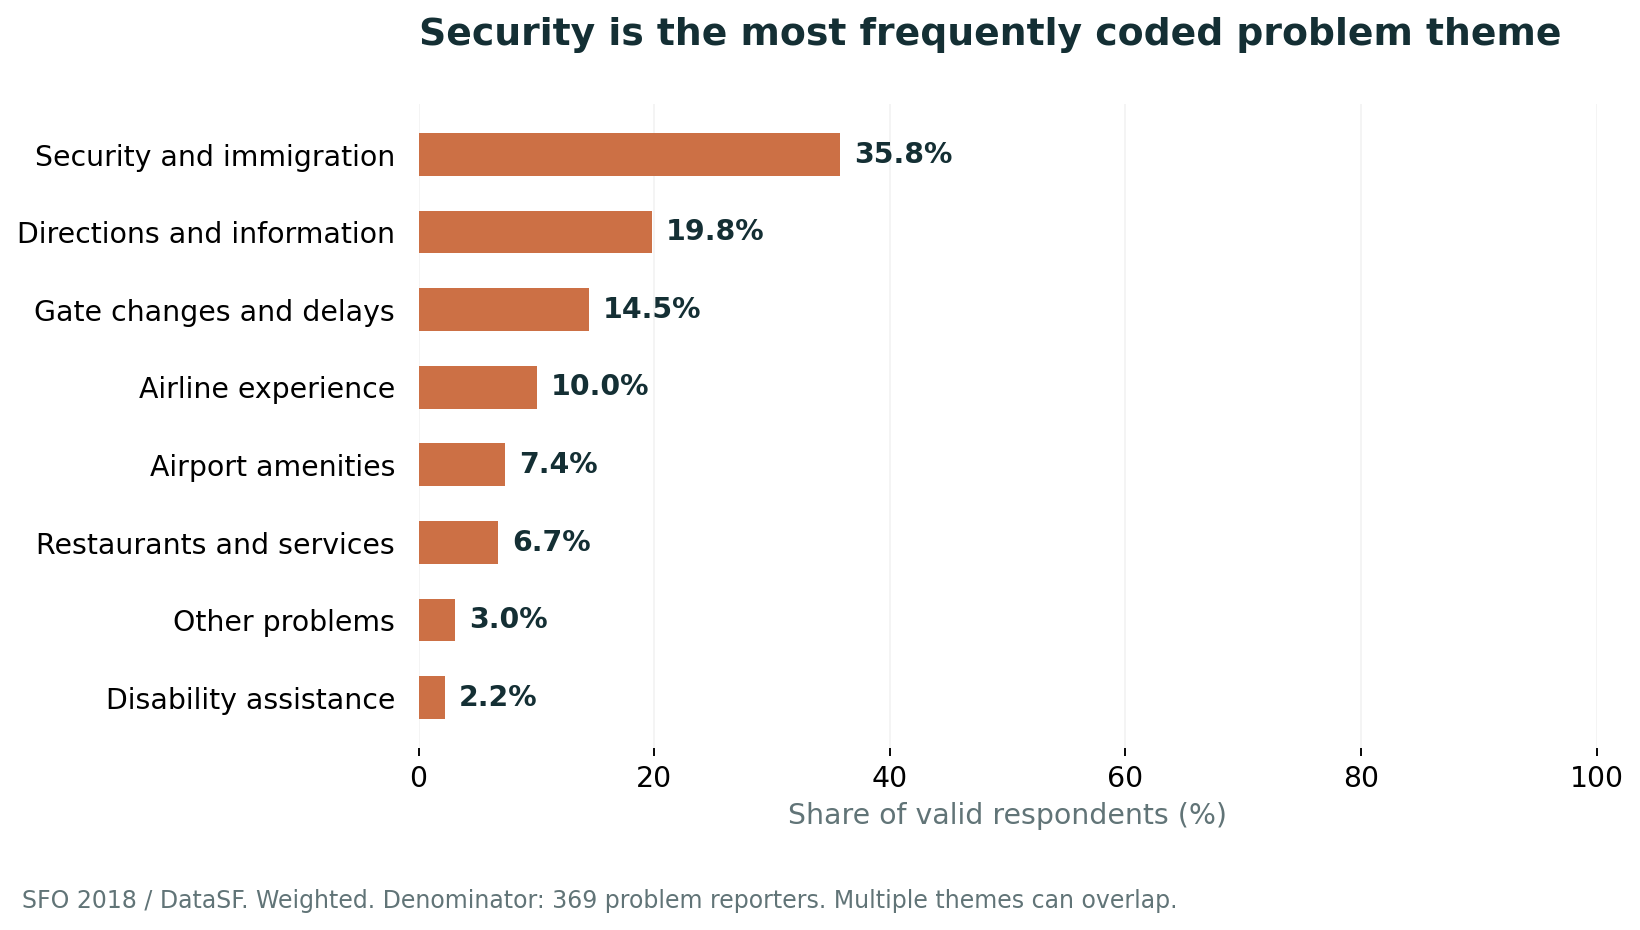

In [6]:
from sfo_cx.analysis import THEMES
keys = ['theme_' + k for k in THEMES]
display(summarize(df, keys)[['label','n','value']].sort_values('value', ascending=False).round(3))
print('Problem reporters without a recognized theme:', info['problem_reporters_without_recognized_theme_n'])
display(Image(filename=str(ROOT / 'outputs/figures/04_problem_themes.png')))

## 6. Compare services and check usage
All service rankings use each service's valid 1-5 rating base. These bases differ. A same-day usage question can refine the population, but a nonuser that day may still rate a prior experience.

Wi-Fi shows the distinction: about 73% rate it 4/5 among all valid raters, compared with about 82% among same-day users who rated it validly. We retain source inconsistencies and handle them with explicit flags.

,label,n,value
4,Walkways and elevators: rating 4 or 5,2537,79.02
5,Flight information screens: rating 4 or 5,2611,78.64
3,Indoor signs and directions: rating 4 or 5,2648,78.33
11,AirTrain: rating 4 or 5,1309,75.75
8,Free Wi-Fi: rating 4 or 5,2074,73.12
9,Roadway signs: rating 4 or 5,1772,71.81
0,Artwork and exhibitions: rating 4 or 5,2160,71.28
7,Information: departures: rating 4 or 5,1529,68.18
6,Information: arrivals: rating 4 or 5,1518,66.95
13,Rental car center: rating 4 or 5,910,65.53


,service,usage_group,n,value
0,Restaurants,All valid raters,2342,56.84
1,Restaurants,Used/purchased today: Yes,1309,56.65
2,Restaurants,Used/purchased today: No,833,57.18
3,Retail shops,All valid raters,2277,54.69
4,Retail shops,Used/purchased today: Yes,1016,55.25
5,Retail shops,Used/purchased today: No,1016,53.35
6,Free Wi-Fi,All valid raters,2074,73.12
7,Free Wi-Fi,Used/purchased today: Yes,1353,82.43
8,Free Wi-Fi,Used/purchased today: No,582,54.24


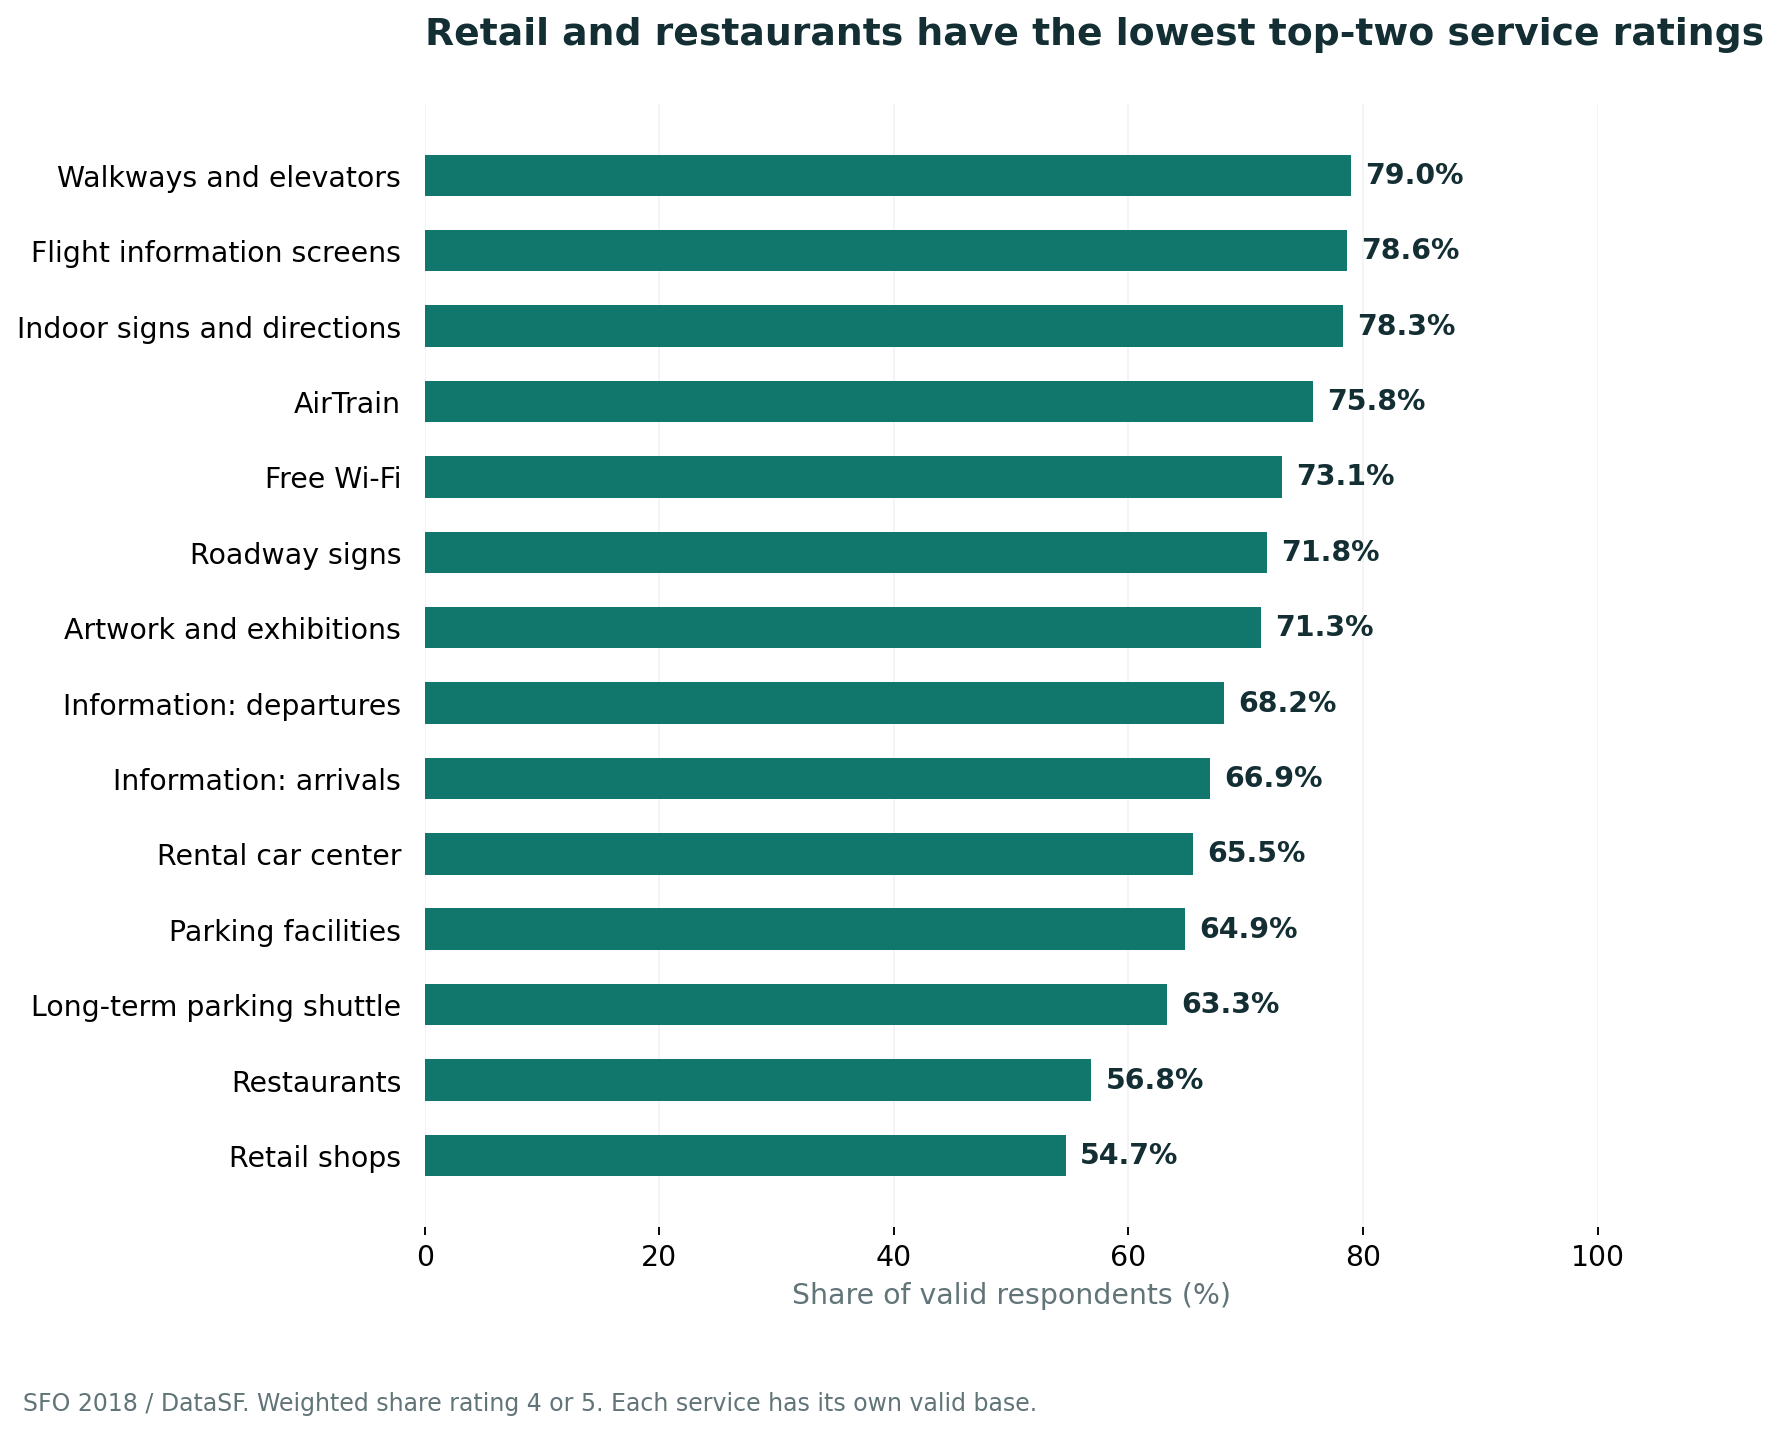

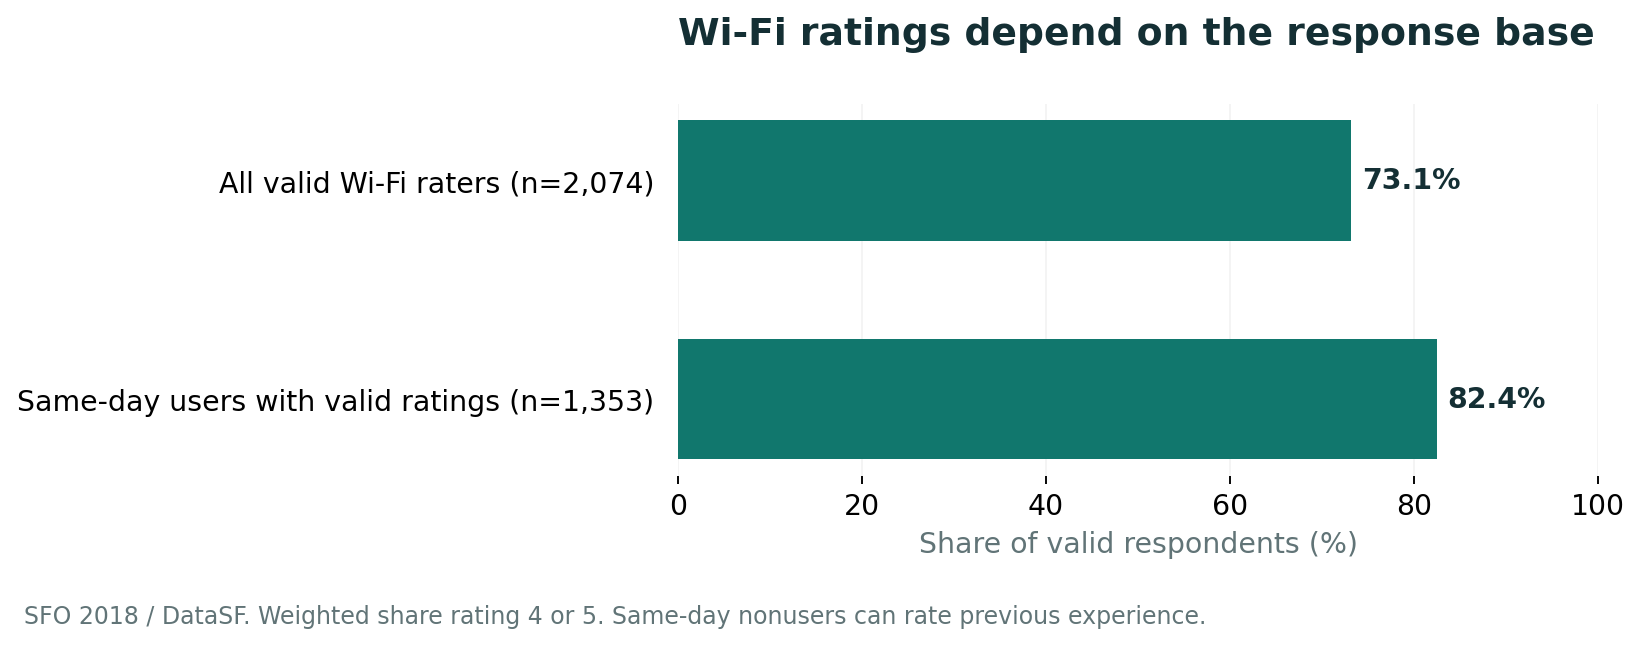

In [7]:
display(summarize(df, list(SERVICES))[['label','n','value']].sort_values('value', ascending=False).round(2))
display(usage_sensitivity(df)[['service','usage_group','n','value']].round(2))
display(Image(filename=str(ROOT / 'outputs/figures/03_service_ratings.png')))
display(Image(filename=str(ROOT / 'outputs/figures/06_wifi_usage.png')))

## 7. Explore co-rating associations without treating them as causal drivers
Spearman correlations respect the ordinal ranking of the 1-5 answers. This exploratory table is deliberately **unweighted**, while headline percentages are weighted. Each service/overall pair has its own valid response base.

Common sentiment, questionnaire context and service use can influence both ratings. The correlations are not incremental effects, validated importance weights or ROI estimates.

In [8]:
display(rating_associations(df)[['service','pair_n','spearman_rho','weighted']].round(3))

,service,pair_n,spearman_rho,weighted
12,Long-term parking shuttle,631,0.614,False
7,Information: departures,1471,0.606,False
10,Parking facilities,1040,0.594,False
13,Rental car center,879,0.579,False
6,Information: arrivals,1460,0.577,False
3,Indoor signs and directions,2543,0.573,False
1,Restaurants,2249,0.567,False
5,Flight information screens,2505,0.562,False
2,Retail shops,2180,0.557,False
4,Walkways and elevators,2432,0.540,False


## 8. Challenge the result
Compare weighted and unweighted metrics. Holding boarding-area mix fixed provides one descriptive check on the NPS gap, but some problem/area cells have only eight respondents. No formal causal or significance claim follows.

Kish effective n describes concentration of weights. The two input files do not establish a full design-based variance analysis, so no p-values or formal confidence intervals are reported.

In [9]:
keys = ['overall_top2','problem_rate','nps']
comparison = summarize(df, keys)[['metric','value','n','effective_n_kish']].merge(
    summarize(df, keys, weighted=False)[['metric','value']], on='metric',
    suffixes=('_weighted','_unweighted'))
display(comparison.round(3))
display(standardized_nps(df).round(3))
display(by_group(df, 'visit_type', ['nps','overall_top2'])[['group','label','n','value']].round(2))

,metric,value_weighted,n,effective_n_kish,value_unweighted
0,overall_top2,80.485,2625,2128.353,78.438
1,problem_rate,12.882,2616,2109.467,14.106
2,nps,35.114,2650,2134.243,30.981


,problem_status,n,boarding_areas,unadjusted_nps,area_standardized_nps,minimum_area_cell_n
0,Reported a problem,359,"A,B,C,D,E,F,G",-1.905,0.358,8
1,Reported no problem,2181,"A,B,C,D,E,F,G",41.461,41.336,143


,group,label,n,value
0,First-time passenger,Net Promoter Score,570,27.04
1,First-time passenger,Airport overall: rating 4 or 5,547,80.74
2,Returning passenger,Net Promoter Score,2063,37.44
3,Returning passenger,Airport overall: rating 4 or 5,2061,80.41


## 9. Turn the evidence into a follow-up plan
Investigate security issues with relevant partners, assess dining/retail value and service with targeted questions, and define an actual-user digital-experience measure. Track operational outcomes in a pilot before claiming improvement effects.

**Learning exercise:** choose a boarding area and reproduce its NPS, valid base and overall-rating share. Explain why this subgroup may differ before making an operational recommendation.

In [10]:
selected_area = 'A'  # change to another included area
display(summarize(df.loc[df.BAREA.eq(selected_area)], ['nps','overall_top2','problem_rate'])[['label','unit','n','value']].round(3))

,label,unit,n,value
0,Net Promoter Score,points,661,27.310
1,Airport overall: rating 4 or 5,percent,648,75.567
2,Reported a problem,percent,658,19.526


## Reproduce, edit and publish
From the project root, run `python scripts/run_analysis.py` and then `python -m unittest discover -s tests -v`.

Edit `reports/case_study_template.md` for report text and `presentation/carousel_content.json` for slide wording. Rebuild to update the generated report and PDF. These editable sources survive reruns. Read `docs/editing_and_github.md` before uploading.

Source: [2018 SFO Customer Survey, DataSF](https://data.sf.gov/Transportation/2018-SFO-Customer-Survey/3w8r-nuxp). All calculations are independent, historical 2018 estimates. No SFO endorsement is implied.